# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [3]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

Country
China          253.2
India          195.2
Indonesia      143.1
South Korea     80.2
Japan          -25.8
Name: CO2_Mt, dtype: float64


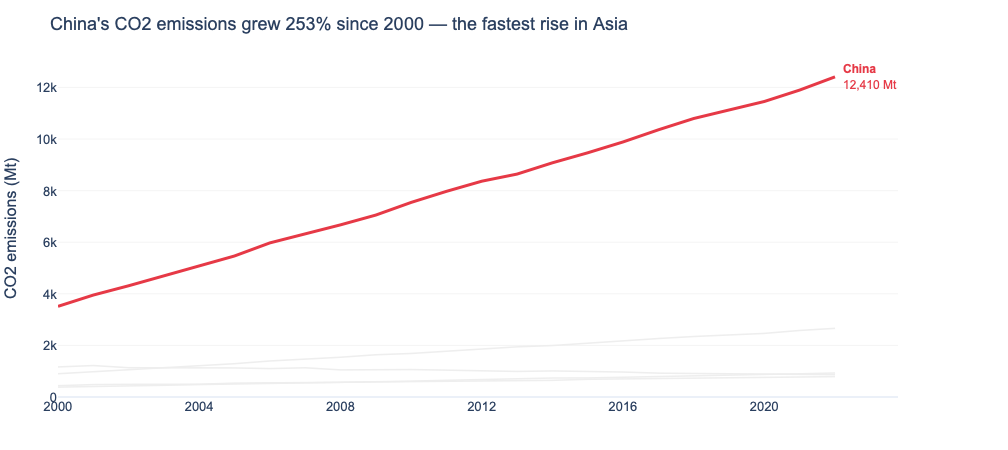

In [5]:
# Task — Multi-series line with highlight
# ---------------------------------------
asia = df[df['Region'] == 'Asia'].copy()

# Pick the country to highlight: the fastest CO2 growth 2000 -> 2022
first, last = asia['Year'].min(), asia['Year'].max()
start = asia[asia['Year'] == first].set_index('Country')['CO2_Mt']
end = asia[asia['Year'] == last].set_index('Country')['CO2_Mt']
growth = ((end / start - 1) * 100).sort_values(ascending=False)
print(growth.round(1))

highlight = growth.index[0]
pct = growth.iloc[0]
color_map = {c: '#E63946' if c == highlight else '#EEEEEE' for c in asia['Country'].unique()}

fig = px.line(
    asia, x='Year', y='CO2_Mt', color='Country',
    color_discrete_map=color_map,
    labels={'CO2_Mt': 'CO2 emissions (Mt)', 'Year': ''},
    title=f"{highlight}'s CO2 emissions grew {pct:.0f}% since {first} — the fastest rise in Asia",
    template='plotly_white',
    height=450
)

# Context lines: thin, no legend
fig.update_traces(line=dict(width=1.5), showlegend=False)
# Highlighted line: thicker, drawn on top
fig.update_traces(line=dict(width=3), selector=dict(name=highlight))
fig.data = tuple(sorted(fig.data, key=lambda t: t.name == highlight))

# Direct label at the end of the highlighted line
y_end = end[highlight]
fig.add_annotation(
    x=last, y=y_end, text=f"<b>{highlight}</b><br>{y_end:,.0f} Mt",
    showarrow=False, xanchor='left', xshift=6,
    font=dict(color='#E63946', size=12, family='Arial'), align='left'
)

fig.update_layout(
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=False, showline=False, dtick=4),
    yaxis=dict(gridcolor='#F5F5F5', rangemode='tozero', showline=False),
    margin=dict(l=10, r=110, t=60, b=40)
)
fig.show()
